# Trading Pipeline — Exploration
Inspect candles, technicals, prompts, and DB. Import-only from the flat scripts.

In [1]:
import os
os.environ['DATA_SOURCE'] = 'csv'   # change to 'yfinance' if needed

import json, sqlite3, pandas as pd
from technicals import TechnicalsAnalyzer
from pipeline   import build_prompt, DB_PATH

SYMBOL = 'CANBK'
DATE   = '2024-10-10'

ta = TechnicalsAnalyzer()
print('Ready')

Ready


## 1 — Candles

In [2]:
df = ta.load_candles(SYMBOL, DATE, lookback_days=30)
df.tail(10)

,open,high,low,close,volume
2024-09-26,104.99,106.87,103.49,106.57,32778869
2024-09-27,106.89,109.38,106.25,108.95,117791617
2024-09-30,109.09,109.57,106.98,107.20,20238287
2024-10-01,107.21,108.57,106.18,106.73,17564365
2024-10-03,104.26,106.67,103.49,104.12,25792371
2024-10-04,104.26,106.53,102.83,104.03,22631036
2024-10-07,104.50,105.28,98.80,100.20,39132535
2024-10-08,100.11,101.66,99.15,101.59,16636280
2024-10-09,102.29,102.62,99.95,100.83,28405147
2024-10-10,101.48,102.90,100.31,100.55,12399367


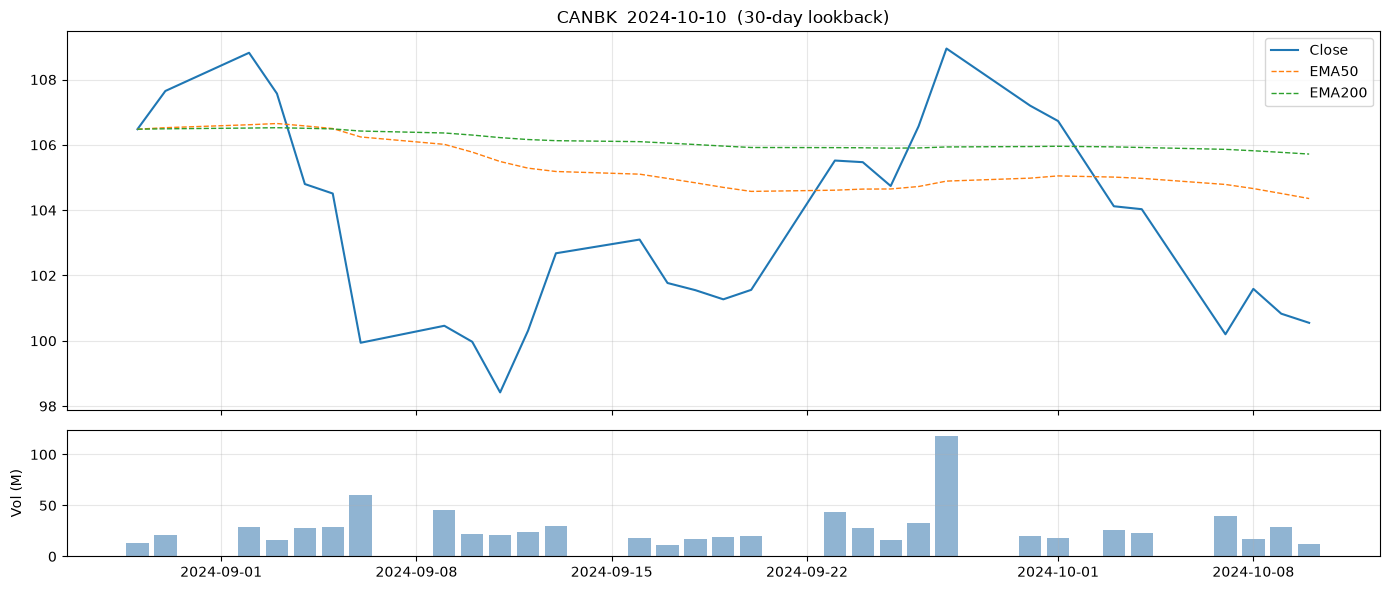

In [3]:
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True,
                                gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(df.index, df['close'], label='Close')
ax1.plot(df.index, df['close'].ewm(span=50,  adjust=False).mean(), '--', lw=1, label='EMA50')
ax1.plot(df.index, df['close'].ewm(span=200, adjust=False).mean(), '--', lw=1, label='EMA200')
ax1.set_title(f'{SYMBOL}  {DATE}  (30-day lookback)')
ax1.legend(); ax1.grid(alpha=0.3)
ax2.bar(df.index, df['volume'] / 1e6, color='steelblue', alpha=0.6)
ax2.set_ylabel('Vol (M)'); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2 — Technicals

In [4]:
tech = ta.compute(df)
vc   = ta.vix_context(DATE)
zc   = ta.compute_zones(SYMBOL, DATE)

for k, v in tech.items():
    if k not in ('recent_candles',):
        print(f'  {k:25s}: {v}')

  close                    : 100.55
  ema_50                   : 104.36
  ema_100                  : 105.14
  ema_200                  : 105.72
  vwap                     : 103.97
  ema_stack                : bearish (50<100<200)
  above_vwap               : False
  above_ema200             : False
  trend                    : ranging
  structure                : []
  nearest_support          : {'low': 97.21, 'high': 97.21, 'mid': 97.21}
  nearest_resistance       : {'low': 109.57, 'high': 109.57, 'mid': 109.57}
  support_zones            : [{'low': 97.21, 'high': 97.21, 'mid': 97.21}]
  resistance_zones         : [{'low': 109.57, 'high': 109.57, 'mid': 109.57}]
  swing_highs              : [{'date': '2024-09-30', 'price': 109.57}]
  swing_lows               : [{'date': '2024-09-09', 'price': 97.21}]
  swing_highs_30d          : [{'date': '2024-09-03', 'price': 109.54}, {'date': '2024-09-16', 'price': 104.44}, {'date': '2024-09-30', 'price': 109.57}]
  swing_lows_30d           : [{'dat

In [5]:
print('VIX:', vc)
print('Zones:', json.dumps(zc, indent=2))

VIX: {'vix': 12.11, 'pctile_1y': 3, 'regime': 'LOW', 'dir_5d': 'falling', 'pos_20d': 'bottom', 'regime_trading': 'sideways', 'trend_10d': 'falling', 'quantity_bias': 'standard sizing'}
Zones: {
  "tf_5min": {},
  "tf_1h": {
    "supply": {
      "kind": "supply",
      "low": 103.65,
      "high": 104.25,
      "formed": 92,
      "touches": 0,
      "fresh": true,
      "valid": true,
      "dist_pct": 3.08
    }
  },
  "confluence": {
    "demand": false,
    "supply": false
  }
}


## 3 — LLM Prompt Preview

In [6]:
prompt = build_prompt(SYMBOL, DATE, tech, vc, zc)
print(prompt)
print(f'\n~{len(prompt)//4} tokens')

[CANBK 2024-10-10 @close]
HEADLINE: bias:bearish | trend:ranging | PDH:rejected | VIX:LOW
C:100.55 (-0.28%) | 5d:98.8-106.53 C@23pct
ATR:3.59 | Vol:12.4M(0.52x avg) | 3d:+0.35%
VOL_TREND: 5d:23.8M 20d:28.0M (0.85x) | potential_base

EMA: 50@104.36 < 100@105.14 < 200@105.72 [BEARISH]
VWAP:103.97 C-3.29% | C vs EMA200:-4.89%
Trend:ranging | Struct:-

S:97.2-97.2(-3.3%)  (nearest -3.3%)
R:109.6-109.6(+9.0%)  (nearest +8.97%)
ROUND: 100.0(M,-0.6%)
SWH/L-90d: H:109.6(09-30)  L:97.2(09-09)
SWH/L-30d: H:109.5(09-03)  104.4(09-16)  109.6(09-30)  L:97.2(09-09)  99.2(09-19)  103.5(09-26)  98.8(10-07)
LEVELS: PDH 102.62(rejected) | PDL 99.95(above) | 2DH 102.62(intact) | 2DL 99.15(intact) | 3DH 105.28(intact) | 3DL 98.8(intact) | WkH 109.57(below) | WkL 102.83(lost)
VIX:12.11 | 3pct(1y) | LOW | sideways | 5d:falling 10d:falling | 20dRange:bottom | size:standard sizing
ZONES:
  5m  DZ:— SZ:—
  1h  DZ:— SZ:103.65-104.25 fresh(+3.1%)


~233 tokens


## 4 — DB Contents

In [7]:
with sqlite3.connect(DB_PATH) as con:
    df_db = pd.read_sql(
        'SELECT symbol, decision_date, action, entry_price, stop_loss, take_profit, '
        'exit_reason, pnl, confidence FROM trade_log ORDER BY decision_date DESC LIMIT 20',
        con)
df_db

,symbol,decision_date,action,entry_price,stop_loss,take_profit,exit_reason,pnl,confidence
0,CANBK,2024-10-21,HOLD,99.15,0.00,0.00,HOLD,0.0,0.40
1,CANBK,2024-10-10,HOLD,100.55,0.00,0.00,HOLD,0.0,0.40
2,CANBK,2024-06-21,HOLD,115.32,0.00,0.00,HOLD,0.0,0.80
3,CANBK,2024-04-24,HOLD,112.16,0.00,0.00,HOLD,0.0,0.40
4,CANBK,2023-02-21,HOLD,130.93,0.00,0.00,HOLD,0.0,0.58
5,CANBK,2023-02-15,HOLD,74.44,0.00,0.00,HOLD,0.0,0.62
6,CANBK,2023-02-09,HOLD,144.95,0.00,0.00,HOLD,0.0,0.64
7,CANBK,2023-02-07,BUY,75.14,73.45,79.25,TP_HIT,41.1,0.74
8,CANBK,2023-01-31,HOLD,55.39,0.00,0.00,HOLD,0.0,0.87
9,CANBK,2023-01-23,SELL,133.87,136.00,129.36,TIME_EXIT,4.4,0.66


In [8]:
with sqlite3.connect(DB_PATH) as con:
    stats = pd.read_sql(
        "SELECT action, exit_reason, COUNT(*) n, ROUND(AVG(pnl),2) avg_pnl, "
        "ROUND(SUM(pnl),2) total_pnl FROM trade_log GROUP BY action, exit_reason",
        con)
stats

,action,exit_reason,n,avg_pnl,total_pnl
0,BUY,ENTRY_NOT_FILLED,1,0.00,0.0
1,BUY,SL_HIT,3,-18.83,-56.5
2,BUY,TIME_EXIT,3,9.93,29.8
3,BUY,TP_HIT,10,40.93,409.3
4,HOLD,HOLD,24,0.00,0.0
5,SELL,SL_HIT,3,-15.67,-47.0
6,SELL,TIME_EXIT,6,-4.58,-27.5
7,SELL,TP_HIT,6,33.97,203.8


## 5 — Training Example Preview

In [9]:
from splitter import load_trades, build_example

trades = load_trades(DB_PATH)
print(f'{len(trades)} trades in DB')

if trades:
    ex = build_example(trades[0])
    for msg in ex['messages']:
        print(f"\n--- {msg['role'].upper()} ---")
        print(msg['content'][:600])

0 trades in DB


## 6 — Forward Candles (outcome check)

In [10]:
fwd = ta.load_forward(SYMBOL, DATE, n=5)
fwd[['open','high','low','close','volume']]

,open,high,low,close,volume
date,,,,,
2024-10-11 09:15:00,100.98,101.03,100.57,100.69,240662
2024-10-11 09:16:00,100.77,100.87,100.63,100.70,221286
2024-10-11 09:17:00,100.70,100.70,100.36,100.42,218547
2024-10-11 09:18:00,100.40,100.49,100.34,100.40,67129
2024-10-11 09:19:00,100.40,100.43,100.31,100.39,131200
...,...,...,...,...,...
2024-10-17 15:25:00,98.87,98.91,98.86,98.89,45217
2024-10-17 15:26:00,98.90,98.94,98.89,98.93,60354
2024-10-17 15:27:00,98.88,98.94,98.86,98.87,52873


## 7 — Split DB → JSONL (run before training)

In [11]:
from splitter import build_dataset

counts = build_dataset(
    db_path      = DB_PATH,
    out_path     = "data/trading.jsonl",
    min_confidence = 0.5,
    min_rr         = 1.5,
    val_ratio      = 0.1,
    test_ratio     = 0.1,
)
print(counts)

Loaded 0 trades from trading_agent.db
Built 0 raw examples
After quality filter: 0 examples
  After dedup:   0 (removed 0 duplicates)
Split: time (walk-forward) | embargo removed 0 val/test examples
  train:    0 examples → data\trading_train.jsonl
  val  :    0 examples → data\trading_val.jsonl
  test :    0 examples → data\trading_test.jsonl
{'train': 0, 'val': 0, 'test': 0}


## 8 — Train (PyTorch LoRA — MPS / CUDA / CPU)
> Runs overnight (~8-12h on M5 for 3 epochs). Output streamed to `output/train.log`. Set `EPOCHS=1` for a quick smoke-test.

In [12]:
import subprocess, pathlib, os

TRAIN_JSONL = "data/trading_train.jsonl"
VAL_JSONL   = "data/trading_val.jsonl"
MODEL       = os.environ.get("BASE_MODEL", "nvidia/Nemotron-Mini-4B-Instruct")
OUTPUT_DIR  = "output/nemotron-lora"
LOG_FILE    = "output/train.log"
EPOCHS      = 1    # set to 3 for full training; 1 for smoke-test

pathlib.Path("output").mkdir(exist_ok=True)

cmd = [
    "python", "train.py",
    "--train",      TRAIN_JSONL,
    "--val",        VAL_JSONL,
    "--model",      MODEL,
    "--output_dir", OUTPUT_DIR,
]
env = os.environ.copy()
env["EPOCHS"] = str(EPOCHS)

print("Starting training — logging to", LOG_FILE)
print("Command:", " ".join(cmd))
print(f"Device: MPS (Apple Silicon) | Epochs: {EPOCHS}")
print("View live metrics: run 'mlflow ui' in terminal → http://localhost:5000")

with open(LOG_FILE, "w") as log:
    proc = subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT, env=env)

print(f"\nPID {proc.pid} — re-run the loss graph cell below to track progress")
print("After training finishes, merge the adapter:")
print(f"  python train.py --merge --adapter {OUTPUT_DIR} --base_model {MODEL}")


Starting training — logging to output/train.log
Command: python train.py --train data/trading_train.jsonl --val data/trading_val.jsonl --model nvidia/Nemotron-Mini-4B-Instruct --output_dir output/nemotron-lora
Device: MPS (Apple Silicon) | Epochs: 1
View live metrics: run 'mlflow ui' in terminal → http://localhost:5000



PID 33464 — re-run the loss graph cell below to track progress


After training finishes, merge the adapter:
  python train.py --merge --adapter output/nemotron-lora --base_model nvidia/Nemotron-Mini-4B-Instruct


## 9 — Loss Graph (re-run any time to refresh)

In [13]:
import re, matplotlib.pyplot as plt, json

# HuggingFace Trainer logs to stdout — each step looks like:
#   {"loss": 2.345, "grad_norm": ..., "learning_rate": ..., "epoch": 0.5}
# or formatted as:
#   {'loss': 2.345, 'grad_norm': ..., 'epoch': 0.5}
train_steps, train_loss = [], []
eval_steps,  eval_loss  = [], []
step = 0

try:
    with open(LOG_FILE) as f:
        for line in f:
            line = line.strip()
            # HF Trainer JSON log lines
            for pat in (r'\{.*"loss".*\}', r"\{.*'loss'.*\}"):
                m = re.search(pat, line)
                if m:
                    try:
                        d = json.loads(m.group().replace("'", '"'))
                        step += 1
                        if "loss" in d:
                            train_steps.append(step)
                            train_loss.append(float(d["loss"]))
                        if "eval_loss" in d:
                            eval_steps.append(step)
                            eval_loss.append(float(d["eval_loss"]))
                    except Exception:
                        pass
            # Plain text fallback: "{'loss': X, ...}"
            m = re.search(r"'loss':\s*([\d.]+)", line)
            if m and not train_loss:
                step += 1
                train_steps.append(step)
                train_loss.append(float(m.group(1)))
            m = re.search(r"'eval_loss':\s*([\d.]+)", line)
            if m:
                eval_steps.append(step)
                eval_loss.append(float(m.group(1)))
except FileNotFoundError:
    print(f"Log not found: {LOG_FILE} — run the training cell first")

if train_loss:
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(train_steps, train_loss, label="Train loss", color="steelblue")
    if eval_loss:
        ax.plot(eval_steps, eval_loss, label="Val loss", color="tomato", marker="o", ms=4)
    ax.set_xlabel("Step"); ax.set_ylabel("Loss")
    ax.set_title("Training Loss — HuggingFace Trainer")
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    print(f"Last train loss: {train_loss[-1]:.4f}  |  steps so far: {train_steps[-1]}")
    if eval_loss:
        print(f"Last val   loss: {eval_loss[-1]:.4f}")
else:
    print("No loss data yet — training may still be starting up or logging hasn't begun")


No loss data yet — training may still be starting up or logging hasn't begun


## 10 — Evaluate (after training finishes)

In [14]:
import json
from pathlib import Path
from evaluate import evaluate_model_quality, trading_metrics, pnls_from_test_meta

TEST_JSONL   = "data/trading_test.jsonl"
FUSED_MODEL  = None   # set to "output/nemotron-lora/fused_model" after training + merge

# ── Self-check (no model required) ──────────────────────────────────────────
# Echoes stored answers → expect ~100% on all quality metrics. Good harness test.
rows = [json.loads(l) for l in open(TEST_JSONL) if l.strip()]
_answers = {}
for _ex in rows:
    _u = next((m["content"] for m in _ex["messages"] if m["role"] == "user"), "")
    _a = next((m["content"] for m in _ex["messages"] if m["role"] == "assistant"), "")
    _answers[_u] = _a

def _stored_gen(system, user):
    return _answers.get(user, "")

gen_fn = _stored_gen
label  = "self-check (stored answers)"

# ── Use fine-tuned HuggingFace model ────────────────────────────────────────
if FUSED_MODEL and Path(FUSED_MODEL).exists():
    from evaluate import hf_generate_factory
    gen_fn = hf_generate_factory(FUSED_MODEL)
    label  = f"HF fused model: {FUSED_MODEL}"

print(f"Evaluating: {label}")

# ── A) Model quality ──────────────────────────────────────────────────────────
q = evaluate_model_quality(TEST_JSONL, gen_fn)
print("\nMODEL QUALITY (held-out test):")
for k, v in q.items():
    print(f"  {k:20s}: {v}")

# ── B) Trading metrics from recorded outcomes ────────────────────────────────
pnls = pnls_from_test_meta(TEST_JSONL)
if pnls:
    tm = trading_metrics(pnls)
    print("\nTRADING METRICS (recorded P&L on test dates):")
    for k, v in tm.items():
        flag = " ✓" if k == "significant_95" and v else ""
        print(f"  {k:22s}: {v}{flag}")
else:
    print("\nNo P&L data in test meta — run splitter.py first, then re-check")


Evaluating: self-check (stored answers)

MODEL QUALITY (held-out test):
  n                   : 0
  n_decision          : 0
  json_validity       : 0.0
  reasoning_ok        : 0.0
  features_used_ok    : 0.0
  schema_ok           : 0.0
  action_match        : 0.0

No P&L data in test meta — run splitter.py first, then re-check
